# Week 11: DBSCAN and Hierarchical Agglomerative Clustering
## Marketing Conversion Propensity

DBSCAN and HAC are used on three sets of marketing data to discover patterns in customers’ engagement, the effectiveness of campaigns, and purchase behavior of companies. The analysis includes investigation of DBSCAN parameters, detection of noise, hierarchical linkage, and dendrograms. The results of this work will be compared with the results obtained using K-Means in Week 10.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram

pd.set_option("display.max_columns", None)
print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
df1 = pd.read_csv("digital_marketing_campaign_dataset.csv")
df2 = pd.read_csv("marketing_and_product_performance.csv")
df3 = pd.read_csv("companies_clean_734.csv")

print("Digital Marketing Campaign:", df1.shape)
print("Marketing and Product Performance:", df2.shape)
print("Synthetic B2B CRM & Marketing:", df3.shape)

Digital Marketing Campaign: (8000, 20)
Marketing and Product Performance: (10000, 17)
Synthetic B2B CRM & Marketing: (734, 19)


## Dataset 1: Digital Marketing Campaign

### Data Preparation and Feature Scaling

DBSCAN and HAC will make use of AdSpend, ClickThroughRate, WebsiteVisits, TimeOnSite, and EmailClicks in order to spot the pattern of customer engagement. Conversion is not going to be used in clustering and will be analyzed after that process. StandardScaler will normalize the variables.

In [3]:
features1 = [
    "AdSpend",
    "ClickThroughRate",
    "WebsiteVisits",
    "TimeOnSite",
    "EmailClicks"
]

X1 = df1[features1].copy()
scaler1 = StandardScaler()
X1_scaled = scaler1.fit_transform(X1)

print("Original Feature Summary:")
print(X1.describe().round(2))
print("\nScaled Feature Means:")
print(pd.DataFrame(X1_scaled, columns=features1).mean().round(4))
print("\nScaled Feature Standard Deviations:")
print(pd.DataFrame(X1_scaled, columns=features1).std(ddof=0).round(4))

Original Feature Summary:
       AdSpend  ClickThroughRate  WebsiteVisits  TimeOnSite  EmailClicks
count  8000.00           8000.00        8000.00     8000.00      8000.00
mean   5000.94              0.15          24.75        7.73         4.47
std    2838.04              0.08          14.31        4.23         2.86
min     100.05              0.01           0.00        0.50         0.00
25%    2523.22              0.08          13.00        4.07         2.00
50%    5013.44              0.15          25.00        7.68         4.00
75%    7407.99              0.23          37.00       11.48         7.00
max    9997.91              0.30          49.00       15.00         9.00

Scaled Feature Means:
AdSpend            -0.0
ClickThroughRate    0.0
WebsiteVisits      -0.0
TimeOnSite         -0.0
EmailClicks         0.0
dtype: float64

Scaled Feature Standard Deviations:
AdSpend             1.0
ClickThroughRate    1.0
WebsiteVisits       1.0
TimeOnSite          1.0
EmailClicks         1.0
dt

The values of the initial features were on different scales since the AdSpend ranged between 100 and 9,998 while the ClickThroughRate range was between 0.01 and 0.30. All five features after the application of the StandardScaler function had mean values close to zero and a standard deviation of 1. As a result, variables with high values would not influence the calculations of distances for DBSCAN and HAC clustering algorithms.

### DBSCAN Nearest-Neighbor Distance Analysis

10th nearest neighbor graph will help find the appropriate epsilon value for DBSCAN. Any elbow found in the sequence of the Euclidean distance can be considered to be a suitable neighborhood radius.

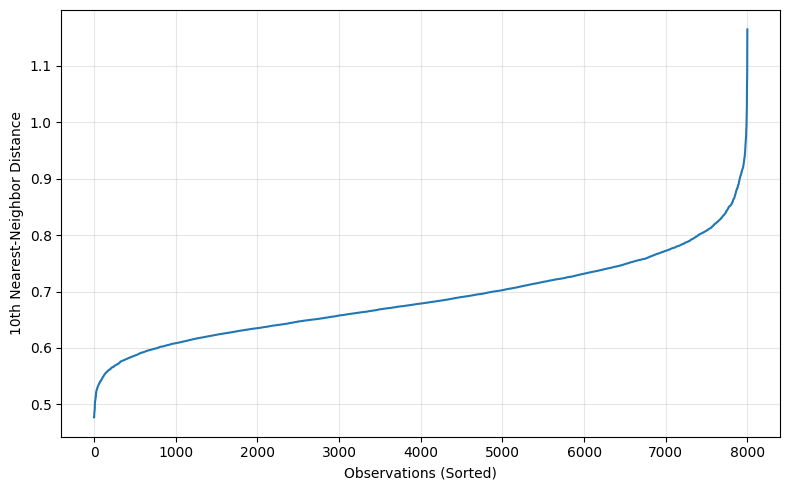

Nearest-Neighbor Distance Percentiles:
50th Percentile: 0.6786
75th Percentile: 0.7315
90th Percentile: 0.7836
95th Percentile: 0.8195
99th Percentile: 0.9066


In [4]:
neighbors1 = NearestNeighbors(
    n_neighbors=10,
    metric="euclidean"
)

neighbors1.fit(X1_scaled)
distances1, indices1 = neighbors1.kneighbors(X1_scaled)
k_distances1 = np.sort(distances1[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances1)
plt.xlabel("Observations (Sorted)")
plt.ylabel("10th Nearest-Neighbor Distance")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Nearest-Neighbor Distance Percentiles:")
for percentile in [50, 75, 90, 95, 99]:
    print(f"{percentile}th Percentile:",
        round(np.percentile(k_distances1, percentile), 4))

The graph depicting the nearest neighbor distance depicted an initial steady rise in distances followed by an abrupt rise towards the end of the graph. Distances at the 90th and 95th percentiles were about 0.78 and 0.82 respectively, meaning that 0.80 can be considered a suitable value for epsilon in DBSCAN. Epsilon values less than 0.80 could result in more noise being identified, while higher epsilon values could lead to the merging of different groups.

### DBSCAN Parameter Exploration

DBSCAN will evaluate epsilon and minimum sample values. Numbers of clusters, noise percentage, and Silhouette values will be considered to find a good configuration.

In [5]:

# epsilon and minimum sample values to test
eps_values1 = [0.70, 0.75, 0.80, 0.85, 0.90, 1.00]
min_samples_values1 = [5, 10, 15]
dbscan_results1 = []

#each combination of DBSCAN parameters being tested
for eps in eps_values1:
    for min_samples in min_samples_values1:
        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric="euclidean"
        )

        labels = dbscan.fit_predict(X1_scaled)
        #clusters counted and percentange of noisepoints
        n_clusters = len(set(labels) - {-1})
        noise_pct = (labels == -1).mean() * 100
        #exclusing noise points when evaluating cluster sep
        non_noise = labels != -1
        # Silhouette score when at least two clusters exist
        if (
            n_clusters >= 2
            and non_noise.sum() > n_clusters
        ):
            score = silhouette_score(
                X1_scaled[non_noise],
                labels[non_noise],
                sample_size=min(2000, non_noise.sum()),
                random_state=42
            )
        else:
            score = np.nan

        # storing results for each parameter combination
        dbscan_results1.append({
            "Epsilon": eps,
            "Min Samples": min_samples,
            "Clusters": n_clusters,
            "Noise (%)": round(noise_pct, 2),
            "Silhouette": round(score, 4)
                if not np.isnan(score) else np.nan
        })

#converting results into a DataFrame for comparison
dbscan_results1_df = pd.DataFrame(dbscan_results1)
print("DBSCAN Parameter Results:")
print(dbscan_results1_df.to_string(index=False))

DBSCAN Parameter Results:
 Epsilon  Min Samples  Clusters  Noise (%)  Silhouette
    0.70            5         1       0.32         NaN
    0.70           10         3       3.78      0.0695
    0.70           15        15      24.81     -0.3568
    0.75            5         1       0.09         NaN
    0.75           10         1       0.62         NaN
    0.75           15         1       4.69         NaN
    0.80            5         1       0.02         NaN
    0.80           10         1       0.11         NaN
    0.80           15         1       0.68         NaN
    0.85            5         1       0.00         NaN
    0.85           10         1       0.00         NaN
    0.85           15         1       0.09         NaN
    0.90            5         1       0.00         NaN
    0.90           10         1       0.00         NaN
    0.90           15         1       0.01         NaN
    1.00            5         1       0.00         NaN
    1.00           10         1       0

The result of testing of parameters for DBSCAN revealed that almost all settings resulted in most of the customers being clustered together in one cluster. When the value of epsilon was set at 0.70 and the minimum samples were set to 10, three clusters and 3.78% noise were generated but a very poor Silhouette score of 0.0695 was obtained. However, when the number of minimum samples increased to 15, 15 clusters and 24.81% noise were found with a negative Silhouette score of -0.3568. Higher values of epsilon resulted in only one cluster.

### DBSCAN Clustering

DBSCAN algorithm will apply epsilon = 0.70 and minimum of 10 samples to form clusters in which there is minimal noise. The size of clusters will be analyzed for balance.

In [6]:
dbscan1 = DBSCAN(
    eps=0.70,
    min_samples=10,
    metric="euclidean"
)

clusters_dbscan1 = dbscan1.fit_predict(X1_scaled)
df1_dbscan = df1.copy()
df1_dbscan["Cluster"] = clusters_dbscan1

# cluster sizes including noise (-1)
print("DBSCAN Cluster Distribution:")
print(df1_dbscan["Cluster"].value_counts().sort_index())
n_clusters1 = len(set(clusters_dbscan1) - {-1})
noise_pct1 = (clusters_dbscan1 == -1).mean() * 100

print("\nNumber of Clusters:", n_clusters1)
print("Noise Percentage:", round(noise_pct1, 2), "%")

DBSCAN Cluster Distribution:
Cluster
-1     302
 0    7686
 1       8
 2       4
Name: count, dtype: int64

Number of Clusters: 3
Noise Percentage: 3.78 %


The DBSCAN algorithm detected three clusters but marked 302 clients (3.78%) as noise. Nevertheless, Cluster 0 comprised 7,686 clients, which accounted for 96.08% of the total number of clients in the database, whereas Clusters 1 and 2 had 8 and 4 clients, respectively. Such an unbalanced proportion means that DBSCAN could detect one large connected cluster but failed to recognize the distinctive groups of customers. Together with the poor value of the Silhouette score (0.0695), this result proves the inefficiency of DBSCAN in clustering customers.

### DBSCAN Cluster Visualization

PCA will reduce the five normalized variables into two dimensions for visualization of the DBSCAN clusters and noise.

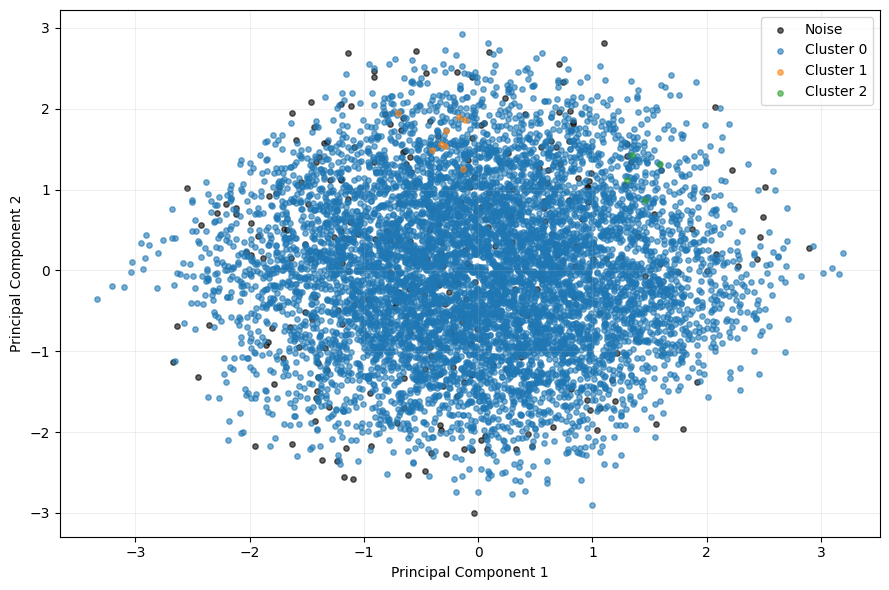

Total Explained Variance: 40.95 %


In [7]:
# Reduce the standardized features to two dimensions
pca_dbscan1 = PCA(n_components=2)
X1_pca_dbscan = pca_dbscan1.fit_transform(X1_scaled)

plt.figure(figsize=(9, 6))
# DBSCAN cluster plotted separately
for cluster in sorted(set(clusters_dbscan1)):
    mask = clusters_dbscan1 == cluster

    if cluster == -1:
        plt.scatter(
            X1_pca_dbscan[mask, 0],
            X1_pca_dbscan[mask, 1],
            c="black",
            s=15,
            alpha=0.6,
            label="Noise"
        )
    else:
        plt.scatter(
            X1_pca_dbscan[mask, 0],
            X1_pca_dbscan[mask, 1],
            s=15,
            alpha=0.6,
            label=f"Cluster {cluster}"
        )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Total Explained Variance:", round(pca_dbscan1.explained_variance_ratio_.sum() * 100, 2),"%")

From the PCA, it was found that the DBSCAN algorithm formed only one major cluster along with two minor clusters and some noise observations. The first two principal components accounted for 40.95% of the variance; therefore, there was no scope of retaining the five-dimensional structure to a great extent. Furthermore, the poor silhouette score of 0.0695 supports the inference that the DBSCAN algorithm has not created any significant clusters. This is in line with the weak cluster separation found using K-Means in Week 10.

### Hierarchical Agglomerative Clustering: Linkage Comparison

The methods that will be considered include single-linkage, complete-linkage, average-linkage, and Ward’s method with clusters ranging from 2 to 6.

In [8]:
#reproducible sample for HAC analysis selected
rng1 = np.random.default_rng(42)
sample_idx1 = rng1.choice(
    len(X1_scaled),
    size=2000,
    replace=False
)

X1_hac = X1_scaled[sample_idx1]
# linkage methods and cluster counts
linkage_methods1 = ["single", "complete", "average", "ward"]
cluster_counts1 = range(2, 7)
hac_results1 = []

#comparing linkage methods using Silhouette scores
for method in linkage_methods1:
    for k in cluster_counts1:
        hac = AgglomerativeClustering(
            n_clusters=k,
            linkage=method,
            metric="euclidean"
        )
        labels = hac.fit_predict(X1_hac)
        score = silhouette_score(
            X1_hac,
            labels
        )
        #storing
        hac_results1.append({
            "Linkage": method,
            "Clusters": k,
            "Silhouette": round(score, 4)
        })

hac_results1_df = pd.DataFrame(hac_results1)

print("HAC Linkage Comparison:")
print(hac_results1_df.to_string(index=False))

HAC Linkage Comparison:
 Linkage  Clusters  Silhouette
  single         2      0.1559
  single         3     -0.0059
  single         4     -0.0717
  single         5     -0.1462
  single         6     -0.1675
complete         2      0.0806
complete         3      0.0745
complete         4      0.0594
complete         5      0.0599
complete         6      0.0612
 average         2      0.0971
 average         3      0.0875
 average         4      0.0717
 average         5      0.0738
 average         6      0.0858
    ward         2      0.1071
    ward         3      0.0955
    ward         4      0.0829
    ward         5      0.0813
    ward         6      0.0889


For Hierarchical Agglomerative Clustering, the performance metrics for single linkage, complete linkage, average linkage, and Ward linkage, based on 2 to 6 clusters, were analyzed. The best results among the linkage techniques in HAC were shown by single linkage, with Silhouette index of 0.1559, followed by Ward linkage (0.1071), average linkage (0.0971), and complete linkage (0.0806). Despite their relative values, all of them were not high, implying low separation of the customer clusters. At the same time, single linkage also demonstrated negative Silhouette indexes in case more clusters were used.

### HAC Dendrogram

The dendrogram from Ward Linkage analysis would be able to demonstrate how the customer clusters join together.

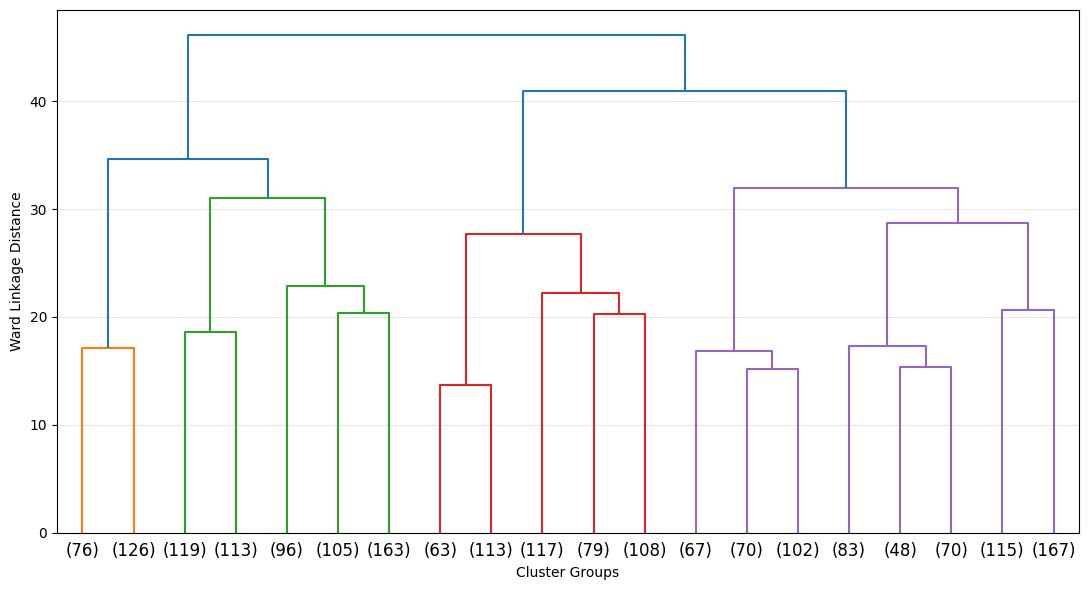

In [9]:
# calculating Ward linkage
linkage_matrix1 = linkage(
    X1_hac,
    method="ward",
    metric="euclidean"
)
#dendrogram plot
plt.figure(figsize=(11, 6))
# final merges
dendrogram(
    linkage_matrix1,
    truncate_mode="lastp",
    p=20,
    show_leaf_counts=True
)

plt.xlabel("Cluster Groups")
plt.ylabel("Ward Linkage Distance")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

From the dendrogram obtained using Ward Linkage Method, it was possible to see the way smaller clusters were gradually combined to form larger clusters. From the results, the last clusters that formed had the distances of approximately 35, 41, and 46. From this, it would mean that either two or three clusters would be a suitable choice. But since Silhouette scores are quite low from the linkage method, customer segments are not clearly separated.

### HAC Cluster Distribution Comparison

Single and Ward linkage will be compared at two clusters to assess whether their group sizes are useful.

In [10]:
# comparing linkage methods
for method in ["single", "ward"]:
    # fit HAC model
    hac = AgglomerativeClustering(
        n_clusters=2,
        linkage=method,
        metric="euclidean"
    )

    labels = hac.fit_predict(X1_hac)

    print(f"\n{method.capitalize()} Linkage:")
    print(pd.Series(labels).value_counts().sort_index())
    print("Silhouette Score:",
        round(silhouette_score(X1_hac, labels), 4))


Single Linkage:
0    1999
1       1
Name: count, dtype: int64
Silhouette Score: 0.1559

Ward Linkage:
0    1202
1     798
Name: count, dtype: int64
Silhouette Score: 0.1071


The single linkage clustering resulted in the highest Silhouette coefficient value of 0.1559; however, 1,999 customers were clustered together while the other cluster only had one customer. It is evident that the clustering technique was not able to find distinct clusters but rather isolated a single observation. The ward clustering algorithm had an almost equal number of observations for both the clusters with a total of 1,202 and 798 customers, although the Silhouette coefficient was much lower at 0.1071.

### HAC Cluster Characteristics and Conversion Rates

Comparison of Ward's clusters will be done based on engagement factors and conversion rate to determine whether the segments differ.

In [11]:
# fit Ward clustering
hac1 = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward",
    metric="euclidean"
)

clusters_hac1 = hac1.fit_predict(X1_hac)
#storing cluster assignments
df1_hac = df1.iloc[sample_idx1].copy()
df1_hac["Cluster"] = clusters_hac1

# cluster average
hac_summary1 = df1_hac.groupby("Cluster")[features1].mean()
#adding customer counts
hac_summary1["Customer_Count"] = (
    df1_hac.groupby("Cluster").size()
)
# conversion rates
hac_summary1["Conversion_Rate"] = (
    df1_hac.groupby("Cluster")["Conversion"].mean() * 100
)

print("HAC Cluster Characteristics:")
print(hac_summary1.round(2).to_string())

HAC Cluster Characteristics:
         AdSpend  ClickThroughRate  WebsiteVisits  TimeOnSite  EmailClicks  Customer_Count  Conversion_Rate
Cluster                                                                                                    
0        6326.16              0.17          26.32        9.00         3.98            1202            91.26
1        3051.26              0.14          22.07        5.84         5.18             798            81.95


Customer groups were discovered using ward clustering. Cluster 0 had 1,202 customers who had high average spend on advertisements, click through rates, number of visits to websites, and amount of time spent on sites with a conversion rate of 91.26%, while Cluster 1 had 798 customers who had low average spending on advertisements and visits to websites but high email click-through rates with a conversion rate of 81.95%. This shows that there was a significant distinction between the groups in terms of conversion rates, although it is evident from the low Silhouette score of 0.1071.

### HAC Cluster Visualization Using PCA

Ward’s customers will be represented by PCA using five standardized variables.

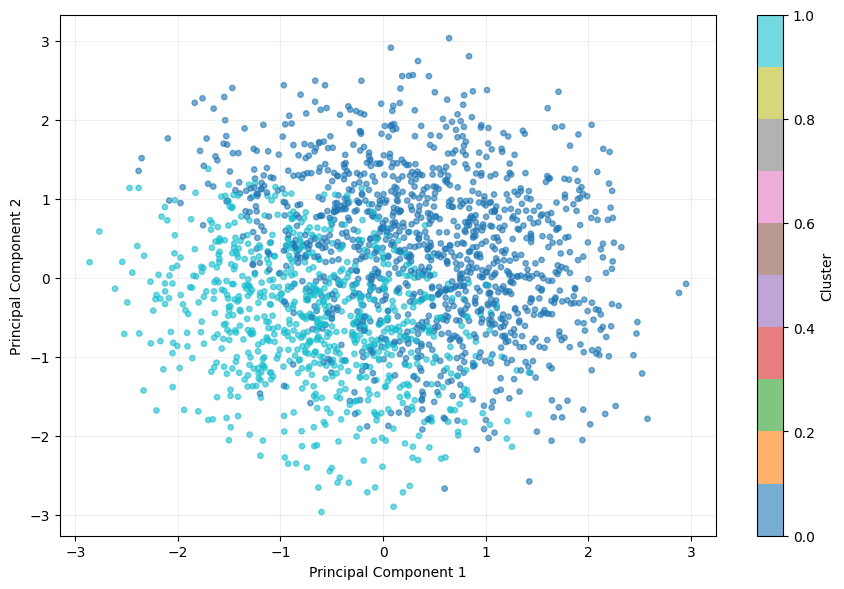

Explained Variance Ratio:
[0.2113 0.2061]

Total Explained Variance: 41.74 %


In [12]:
# reducing feature dimensions
pca_hac1 = PCA(n_components=2)
X1_pca_hac = pca_hac1.fit_transform(X1_hac)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X1_pca_hac[:, 0],
    X1_pca_hac[:, 1],
    c=clusters_hac1,
    cmap="tab10",
    s=15,
    alpha=0.6
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Explained Variance Ratio:")
print(pca_hac1.explained_variance_ratio_.round(4))
print("\nTotal Explained Variance:",
    round(pca_hac1.explained_variance_ratio_.sum() * 100, 2), "%")

PCA visualization exhibited some level of separation between the two clusters using Ward linkage algorithm; however, there was still much overlap close to the origin. The top two components accounted for 41.74% of the total variability; thus, the amount of information included in the visualization was less than 50%. This is in line with the low Silhouette score of 0.1071, which suggests that the customers are not very well-separated even though they have different levels of advertising and conversion rate.

### Dataset 1 Conclusion

The clustering results obtained by DBSCAN algorithm show three extremely unbalanced clusters (Silhouette 0.0695), where 96.08% of customers belong to one cluster. The performance of single-linkage hierarchical clustering was not good (Silhouette 0.1559), but only one observation is separated. Two more suitable clusters were formed by Ward HAC with 1,202 and 798 customers with conversion percentages of 91.26% and 81.95% respectively, but with low Silhouette index of 0.1071 and PCA overlap.

## Dataset 2: Marketing and Product Performance

### Data Preparation and Feature Scaling

DBSCAN and HAC will use Budget, Clicks, Conversions, Units_Sold, and Bundle_Price to create clusters. ROI will not be considered in creating the clusters and will be evaluated later. StandardScaler will normalize features.

In [13]:
features2 = [
    "Budget",
    "Clicks",
    "Conversions",
    "Units_Sold",
    "Bundle_Price"
]

X2 = df2[features2].copy()
# standardize feature values
scaler2 = StandardScaler()
X2_scaled = scaler2.fit_transform(X2)

print("Original Feature Summary:")
print(X2.describe().round(2))
print("\nScaled Feature Means:")
print(pd.DataFrame(X2_scaled, columns=features2).mean().round(4))
print("\nScaled Feature Standard Deviations:")
print(pd.DataFrame(X2_scaled, columns=features2).std(ddof=0).round(4))

Original Feature Summary:
         Budget    Clicks  Conversions  Units_Sold  Bundle_Price
count  10000.00  10000.00     10000.00    10000.00      10000.00
mean   25263.61   2481.90       498.98      100.69        275.20
std    14350.09   1435.97       289.48       57.07        129.22
min      500.44     10.00         1.00        1.00         50.01
25%    12789.19   1225.75       247.00       52.00        165.72
50%    25030.17   2451.00       499.00      101.00        272.56
75%    37921.73   3723.00       751.00      150.00        387.32
max    49999.63   4999.00       999.00      199.00        499.97

Scaled Feature Means:
Budget         -0.0
Clicks         -0.0
Conversions    -0.0
Units_Sold      0.0
Bundle_Price   -0.0
dtype: float64

Scaled Feature Standard Deviations:
Budget          1.0
Clicks          1.0
Conversions     1.0
Units_Sold      1.0
Bundle_Price    1.0
dtype: float64


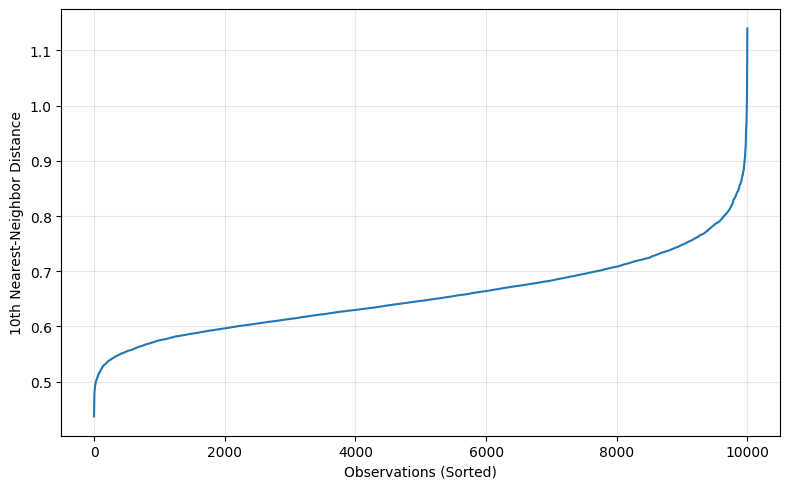

Nearest-Neighbor Distance Percentiles:
50th Percentile: 0.6463
75th Percentile: 0.6951
90th Percentile: 0.7479
95th Percentile: 0.7847
99th Percentile: 0.8603


In [14]:
# neighbor distances
neighbors2 = NearestNeighbors(
    n_neighbors=10,
    metric="euclidean"
)

neighbors2.fit(X2_scaled)
distances2, indices2 = neighbors2.kneighbors(X2_scaled)

# sorting distances
k_distances2 = np.sort(distances2[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances2)
plt.xlabel("Observations (Sorted)")
plt.ylabel("10th Nearest-Neighbor Distance")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("Nearest-Neighbor Distance Percentiles:")
for percentile in [50, 75, 90, 95, 99]:
    print(f"{percentile}th Percentile:", round(np.percentile(k_distances2, percentile), 4))

For the nearest neighbor graph, a steady increase in distances was followed by a steep increase at the end. The 90th and 95th percentiles were about 0.75 and 0.78 respectively, indicating that an epsilon value of between 0.75 and 0.8 could be a good place to start when using DBSCAN. Lower values for epsilon will lead to classifying many campaigns as noise whereas higher values will combine clusters into one big cluster. Further analysis should be conducted to find out the feasibility of forming clusters.

### DBSCAN Parameter Exploration

The DBSCAN algorithm will perform tests on the epsilon and minimum sample values.

In [15]:
eps_values2 = [0.65, 0.70, 0.75, 0.80, 0.85, 0.95]
min_samples_values2 = [5, 10, 15]
dbscan_results2 = []

for eps in eps_values2:
    for min_samples in min_samples_values2:
        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric="euclidean"
        )

        labels = dbscan.fit_predict(X2_scaled)
        n_clusters = len(set(labels) - {-1})
        noise_pct = (labels == -1).mean() * 100
        non_noise = labels != -1

        if n_clusters >= 2 and non_noise.sum() > n_clusters:
            score = silhouette_score(
                X2_scaled[non_noise],
                labels[non_noise],
                sample_size=min(2000, non_noise.sum()),
                random_state=42
            )
        else:
            score = np.nan
        dbscan_results2.append({
            "Epsilon": eps,
            "Min Samples": min_samples,
            "Clusters": n_clusters,
            "Noise (%)": round(noise_pct, 2),
            "Silhouette": round(score, 4)
                if not np.isnan(score) else np.nan
        })

dbscan_results2_df = pd.DataFrame(dbscan_results2)
print("DBSCAN Parameter Results:")
print(dbscan_results2_df.to_string(index=False))

DBSCAN Parameter Results:
 Epsilon  Min Samples  Clusters  Noise (%)  Silhouette
    0.65            5         2       0.58      0.1102
    0.65           10         3       7.32      0.1756
    0.65           15        40      37.71     -0.4053
    0.70            5         1       0.10         NaN
    0.70           10         1       1.27         NaN
    0.70           15         3       8.25     -0.0287
    0.75            5         1       0.04         NaN
    0.75           10         1       0.17         NaN
    0.75           15         1       1.48         NaN
    0.80            5         1       0.01         NaN
    0.80           10         1       0.04         NaN
    0.80           15         1       0.22         NaN
    0.85            5         1       0.01         NaN
    0.85           10         1       0.02         NaN
    0.85           15         1       0.06         NaN
    0.95            5         1       0.00         NaN
    0.95           10         1       0

The DBSCAN parameter analysis proved that the majority of settings clustered almost all the marketing campaigns into just one cluster. The optimal setting was 0.65 value of epsilon with minimum samples equals to 10. It gave the maximum Silhouette score equal to 0.1756 and resulted in identification of 3 clusters and classification of 7.32% of cases as noise. The setting with increased minimum samples to 15 resulted in formation of 40 clusters and 37.71% noise with Silhouette score equal to -0.4053. Greater values of epsilon always clustered the data into one cluster.

### DBSCAN Clustering

DBSCAN will use epsilon 0.65 and 10 minimum samples, the best tested setting by Silhouette score (0.1756). Cluster balance will also be assessed.

In [16]:
dbscan2 = DBSCAN(
    eps=0.65,
    min_samples=10,
    metric="euclidean"
)

clusters_dbscan2 = dbscan2.fit_predict(X2_scaled)
df2_dbscan = df2.copy()
df2_dbscan["Cluster"] = clusters_dbscan2

print("DBSCAN Cluster Distribution:")
print(df2_dbscan["Cluster"].value_counts().sort_index())

n_clusters2 = len(set(clusters_dbscan2) - {-1})
noise_pct2 = (clusters_dbscan2 == -1).mean() * 100

print("\nNumber of Clusters:", n_clusters2)
print("Noise Percentage:", round(noise_pct2, 2), "%")

DBSCAN Cluster Distribution:
Cluster
-1     732
 0    9257
 1       3
 2       8
Name: count, dtype: int64

Number of Clusters: 3
Noise Percentage: 7.32 %


DBSCAN algorithm found three clusters, while 732 campaigns were considered as noise. Yet, Cluster 0 had 9,257 campaigns, which constituted 92.57% of the total set of data, whereas Clusters 1 and 2 had 3 and 8 campaigns respectively. Even though the Silhouette score was larger than the one from Dataset 1 and equal to 0.1756, the very imbalanced distribution implies that DBSCAN algorithm found only one big cluster instead of different segments. Therefore, one can conclude that DBSCAN algorithm is inefficient in segmenting the Marketing and Product Performance dataset.

### DBSCAN Cluster Visualization

PCA will display DBSCAN campaign clusters and noise in two dimensions.

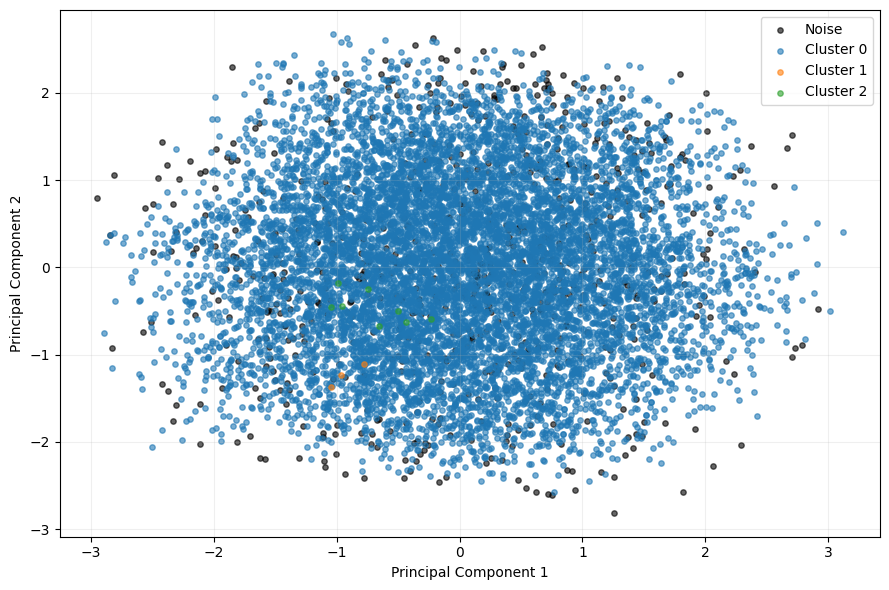

Total Explained Variance: 41.07 %


In [17]:
pca_dbscan2 = PCA(n_components=2)
X2_pca_dbscan = pca_dbscan2.fit_transform(X2_scaled)

plt.figure(figsize=(9, 6))
for cluster in sorted(set(clusters_dbscan2)):
    mask = clusters_dbscan2 == cluster

    if cluster == -1:
        plt.scatter(
            X2_pca_dbscan[mask, 0],
            X2_pca_dbscan[mask, 1],
            c="black",
            s=15,
            alpha=0.6,
            label="Noise"
        )
    else:
        plt.scatter(
            X2_pca_dbscan[mask, 0],
            X2_pca_dbscan[mask, 1],
            s=15,
            alpha=0.6,
            label=f"Cluster {cluster}"
        )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print("Total Explained Variance:", round(pca_dbscan2.explained_variance_ratio_.sum() * 100, 2), "%")

PCA plot revealed that DBSCAN has detected mainly one large cluster related to campaigns, two very small clusters, and some noises. First two principal components have covered 41.07% of the variability in the data set. It means that less than half of the information of the data set has been reflected through PCA plot due to which it is clear that DBSCAN has not detected any segments of the campaigns, even though the value of silhouette score is 0.1756.

### Hierarchical Agglomerative Clustering: Linkage Comparison

The single, complete, average, and Ward linkages will be evaluated using 2 to 6 clusters based on the silhouette index values and number of groups.

In [18]:
rng2 = np.random.default_rng(42)
sample_idx2 = rng2.choice(
    len(X2_scaled),
    size=2000,
    replace=False
)

X2_hac = X2_scaled[sample_idx2]
linkage_methods2 = ["single", "complete", "average", "ward"]
cluster_counts2 = range(2, 7)
hac_results2 = []

for method in linkage_methods2:
    for k in cluster_counts2:
        hac = AgglomerativeClustering(
            n_clusters=k,
            linkage=method,
            metric="euclidean"
        )
        labels = hac.fit_predict(X2_hac)
        score = silhouette_score(
            X2_hac,
            labels
        )
        hac_results2.append({
            "Linkage": method,
            "Clusters": k,
            "Silhouette": round(score, 4)
        })

hac_results2_df = pd.DataFrame(hac_results2)

print("HAC Linkage Comparison:")
print(hac_results2_df.to_string(index=False))

HAC Linkage Comparison:
 Linkage  Clusters  Silhouette
  single         2      0.1113
  single         3      0.0226
  single         4     -0.0178
  single         5     -0.0245
  single         6     -0.1252
complete         2      0.0796
complete         3      0.0719
complete         4      0.0672
complete         5      0.0759
complete         6      0.0556
 average         2      0.1053
 average         3      0.0995
 average         4      0.1006
 average         5      0.1011
 average         6      0.0911
    ward         2      0.0976
    ward         3      0.0850
    ward         4      0.0922
    ward         5      0.0964
    ward         6      0.0945


Hierarchical Agglomerative Clustering was analyzed with single linkage, complete linkage, average linkage, and Ward linkage with 2-6 clusters. The best result was given by single linkage with Silhouette score 0.1113 with 2 clusters, then average linkage with 0.1053, Ward linkage with 0.0976, and complete linkage with 0.0796. All the scores are quite low, which means that there is a poor separation of campaign segments. Negative Silhouette scores have been received with 4 or more clusters from single linkage, but average and Ward linkages were stable.

### HAC Dendrogram

Dendrogram based on Ward linkage will illustrate campaign clustering and indicate potential clusters.

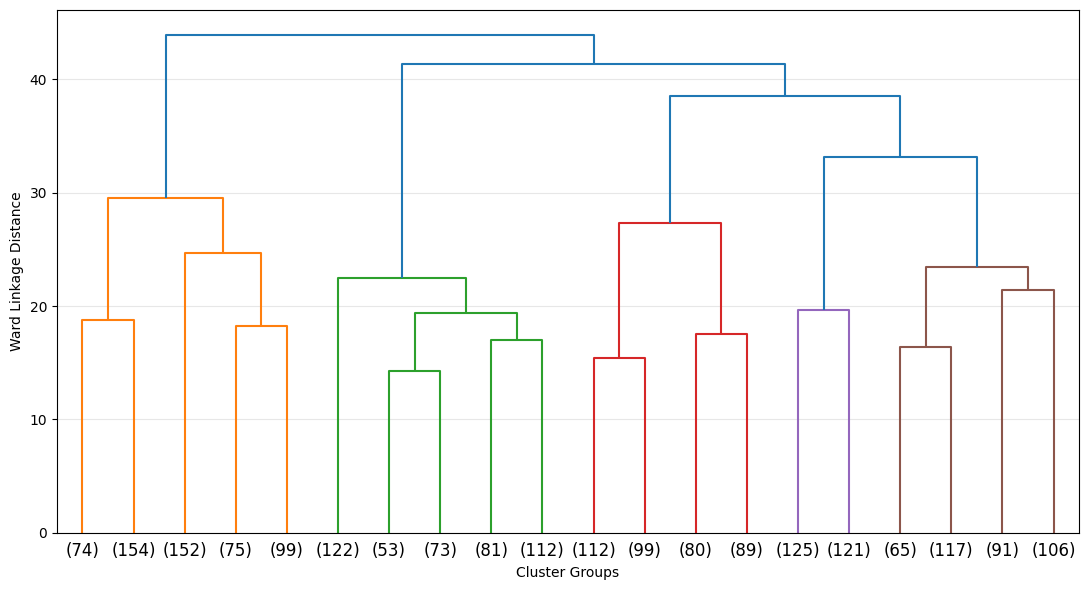

In [19]:
linkage_matrix2 = linkage(
    X2_hac,
    method="ward",
    metric="euclidean"
)

plt.figure(figsize=(11, 6))

dendrogram(
    linkage_matrix2,
    truncate_mode="lastp",
    p=20,
    show_leaf_counts=True
)

plt.xlabel("Cluster Groups")
plt.ylabel("Ward Linkage Distance")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

The small campaign groups have been successively joined together to form larger groups. This was done until the merging of groups happened around 33, 39, 41, and 44 respectively, implying that two to three campaign groups would make sense. But the poor Silhouette scores attained from the linkage method analysis imply that there is not much separation between campaign groups.

### HAC Cluster Distribution Comparison

Single and Ward linkages will be evaluated with the help of two clusters, keeping in view Silhouette and balancing.

In [20]:
for method in ["single", "ward"]:

    hac = AgglomerativeClustering(
        n_clusters=2,
        linkage=method,
        metric="euclidean"
    )
    labels = hac.fit_predict(X2_hac)

    print(f"\n{method.capitalize()} Linkage:")
    print(pd.Series(labels).value_counts().sort_index())
    print("Silhouette Score:", round(silhouette_score(X2_hac, labels), 4))


Single Linkage:
0    1999
1       1
Name: count, dtype: int64
Silhouette Score: 0.1113

Ward Linkage:
0    1446
1     554
Name: count, dtype: int64
Silhouette Score: 0.0976


The best silhouette result of 0.1113 was returned by Single Linkage, but the algorithm formed one cluster out of 1,999 campaigns and only another one cluster out of one campaign. This means that the algorithm managed to isolate a single observation from others. In turn, Ward Linkage resulted in more balanced clusters of 1,446 and 554 campaigns, but with the silhouette value of 0.0976, which was smaller.

### HAC Cluster Characteristics and ROI

Comparison between Ward's two clusters will be based on their characteristics, ROI averages, and high-ROI frequencies.

In [21]:
hac2 = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward",
    metric="euclidean"
)

clusters_hac2 = hac2.fit_predict(X2_hac)
df2_hac = df2.iloc[sample_idx2].copy()
df2_hac["Cluster"] = clusters_hac2
df2_hac["High_ROI"] = (df2_hac["ROI"] > df2["ROI"].median()).astype(int)

hac_summary2 = df2_hac.groupby("Cluster")[features2].mean()
hac_summary2["Campaign_Count"] = (df2_hac.groupby("Cluster").size())
hac_summary2["Average_ROI"] = (df2_hac.groupby("Cluster")["ROI"].mean())
hac_summary2["High_ROI_Rate"] = (df2_hac.groupby("Cluster")["High_ROI"].mean() * 100)

print("HAC Cluster Characteristics:")
print(hac_summary2.round(2).to_string())

HAC Cluster Characteristics:
           Budget   Clicks  Conversions  Units_Sold  Bundle_Price  Campaign_Count  Average_ROI  High_ROI_Rate
Cluster                                                                                                      
0        27375.84  2461.86       592.40       97.28        241.62            1446         2.77          49.79
1        20610.74  2384.49       254.34      110.12        354.97             554         2.69          49.28


Ward clustering revealed two sets of campaign features with distinctive marketing and sales parameters. In the case of Cluster 0, there were 1,446 campaigns, characterized by higher budget and conversion rates; on the contrary, Cluster 1 comprised 554 campaigns, which had low budget and conversion rates and high prices for bundle offers. Nonetheless, the average return on investment was almost the same for both clusters at 2.77 and 2.69, respectively, and High ROI rates were 49.79% and 49.28%. Thus, the results show that HAC recognized differences in campaign features, but they were not related to profitability.

### HAC Cluster Visualization Using PCA

PCA will visualize Ward's two campaign clusters in two dimensions.

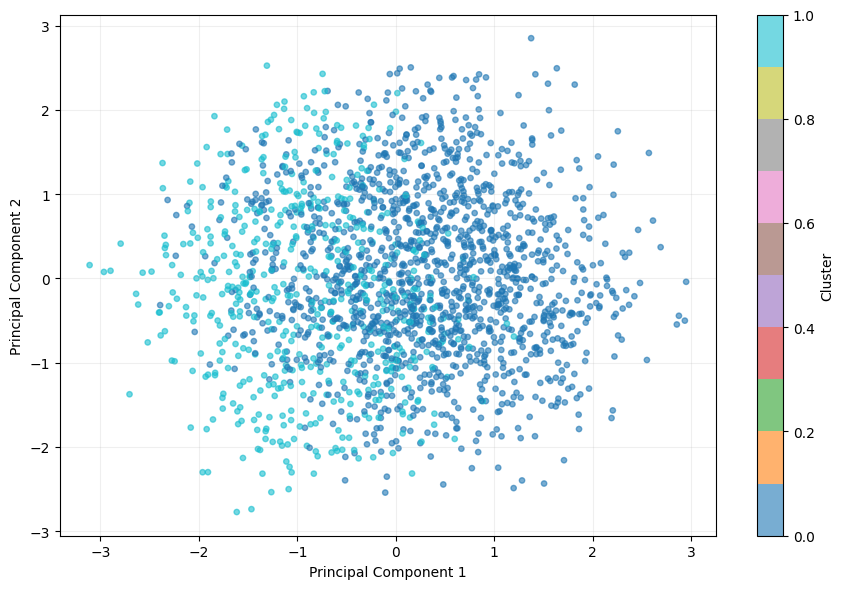

Explained Variance Ratio:
[0.2167 0.2067]

Total Explained Variance: 42.33 %


In [22]:
pca_hac2 = PCA(n_components=2)
X2_pca_hac = pca_hac2.fit_transform(X2_hac)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X2_pca_hac[:, 0],
    X2_pca_hac[:, 1],
    c=clusters_hac2,
    cmap="tab10",
    s=15,
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Explained Variance Ratio:")
print(pca_hac2.explained_variance_ratio_.round(4))
print("\nTotal Explained Variance:", round(pca_hac2.explained_variance_ratio_.sum() * 100, 2), "%")

There was some separation between the two Ward linkage clusters, but there was also overlap between them. The first two components in the visualization captured 42.33% of the total variation, which implies that only less than half of the original information was represented in the visualization. Although Ward linkage could detect differences in budgets, conversions, and prices, the overlapping clusters and Silhouette coefficient of 0.0976 indicate poor cluster separation.

### Dataset 2 Conclusion

Both DBSCAN and Hierarchical Agglomerative Clustering techniques were used on the Marketing and Product Performance dataset to discover campaign segments. The best results for DBSCAN in terms of Silhouette score were gained by using epsilon value 0.65 and 10 minimum samples, resulting in 0.1756 score. At the same time, 92.57% of campaigns were clustered into one cluster, which reduced the significance of the results obtained by DBSCAN algorithm. Two clusters discovered by HAC with Ward linkage had a Silhouette score of 0.0976. Both of the discovered clusters varied from each other in terms of marketing budget, conversions and bundles price, but had similar ROI and High ROI rates.

## Dataset 3: Synthetic B2B CRM & Marketing

### Data Preparation and Feature Scaling

DBSCAN and HAC will be using the variables Annual_Revenue (M₺), Marketing_Spend (K₺), Days_Since_Last_Purchase, and Total_Purchases_Last_Year. The Contract variable will be assessed post-clustering. The variables are standardized by StandardScaler.

In [23]:
features3 = [
    "Annual_Revenue (M₺)",
    "Marketing_Spend (K₺)",
    "Days_Since_Last_Purchase",
    "Total_Purchases_Last_Year"
]

X3 = df3[features3]
scaler3 = StandardScaler()
X3_scaled = scaler3.fit_transform(X3)

print("Original Feature Summary:")
print(X3.describe().round(2))
print("\nScaled Feature Means:")
print(pd.DataFrame(X3_scaled, columns=features3).mean().round(2))
print("\nScaled Feature Standard Deviations:")
print(pd.DataFrame(X3_scaled, columns=features3).std(ddof=0).round(2))

Original Feature Summary:
       Annual_Revenue (M₺)  Marketing_Spend (K₺)  Days_Since_Last_Purchase  \
count               734.00                734.00                    734.00   
mean                 18.33                 21.28                    102.54   
std                  32.29                 10.14                    109.98   
min                   1.00                  5.00                      5.00   
25%                   3.90                 13.00                     21.00   
50%                   7.10                 20.00                     68.00   
75%                  15.28                 28.00                    154.00   
max                 199.40                 50.00                    448.00   

       Total_Purchases_Last_Year  
count                     734.00  
mean                        6.63  
std                         4.68  
min                         0.00  
25%                         2.00  
50%                         5.00  
75%                       

The features were measured using different number ranges, where annual income varied between 1.00 and 199.40 million ₺, while days since last purchase varied between 5 and 448. StandardScaler transformed all four features to have their mean value close to 0 and standard deviation equal to 1. This means that all three financial metrics will affect the clustering calculations made by DBSCAN and Hierarchical Agglomerative Clustering algorithms equally.

### DBSCAN Nearest-Neighbor Distance Analysis

An epsilon value will be chosen using a plot of the 10th nearest neighbor distances.

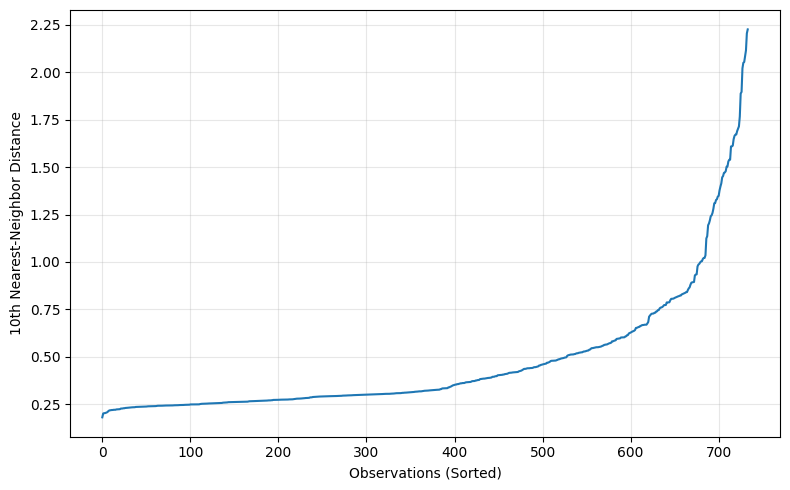

Nearest-Neighbor Distance Percentiles:
50th Percentile: 0.3216
75th Percentile: 0.5314
90th Percentile: 0.8326
95th Percentile: 1.3161
99th Percentile: 1.8932


In [24]:
neighbors3 = NearestNeighbors(
    n_neighbors=10,
    metric="euclidean"
)

neighbors3.fit(X3_scaled)
distances3, indices3 = neighbors3.kneighbors(X3_scaled)
k_distances3 = np.sort(distances3[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances3)
plt.xlabel("Observations (Sorted)")
plt.ylabel("10th Nearest-Neighbor Distance")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("Nearest-Neighbor Distance Percentiles:")
for percentile in [50, 75, 90, 95, 99]:
    print(f"{percentile}th Percentile:", round(np.percentile(k_distances3, percentile), 4))

The nearest neighbor distance graph exhibited an increasing trend followed by a sudden jump at the higher percentiles. The 90th percentile distance was recorded at 0.8326, whereas the 95th percentile value jumped to 1.3161. This implies that epsilon values between 0.80 and 1.00 can be considered as good initial estimates for DBSCAN algorithm. The sudden jump further denotes that some of the businesses have isolation in nature, which may be due to unusual revenues, marketing expenses, and purchases.

### DBSCAN Parameter Exploration

DBSCAN will perform different tests using different epsilon, minimum sample values, comparing cluster counts, noise, and silhouette scores.

In [25]:
eps_values3 = [0.60, 0.70, 0.80, 0.90, 1.00, 1.20]
min_samples_values3 = [5, 10, 15]
dbscan_results3 = []
for eps in eps_values3:
    for min_samples in min_samples_values3:
        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric="euclidean"
        )

        labels = dbscan.fit_predict(X3_scaled)
        n_clusters = len(set(labels) - {-1})
        noise_pct = (labels == -1).mean() * 100
        non_noise = labels != -1

        if n_clusters >= 2 and non_noise.sum() > n_clusters:
            score = silhouette_score(
                X3_scaled[non_noise],
                labels[non_noise]
            )
        else:
            score = np.nan

        dbscan_results3.append({
            "Epsilon": eps,
            "Min Samples": min_samples,
            "Clusters": n_clusters,
            "Noise (%)": round(noise_pct, 2),
            "Silhouette": round(score, 4)
                if not np.isnan(score) else np.nan
        })

dbscan_results3_df = pd.DataFrame(dbscan_results3)

print("DBSCAN Parameter Results:")
print(dbscan_results3_df.to_string(index=False))

DBSCAN Parameter Results:
 Epsilon  Min Samples  Clusters  Noise (%)  Silhouette
     0.6            5         4       7.22      0.2158
     0.6           10         3      12.13      0.3320
     0.6           15         2      17.85      0.4462
     0.7            5         1       6.81         NaN
     0.7           10         1       9.13         NaN
     0.7           15         1      11.99         NaN
     0.8            5         1       6.27         NaN
     0.8           10         1       7.08         NaN
     0.8           15         1       9.26         NaN
     0.9            5         2       4.50      0.4673
     0.9           10         1       6.13         NaN
     0.9           15         1       7.08         NaN
     1.0            5         3       2.45      0.5352
     1.0           10         1       5.59         NaN
     1.0           15         1       5.99         NaN
     1.2            5         1       1.09         NaN
     1.2           10         1       4

The testing of DBSCAN parameters on Dataset 3 demonstrated better clustering results as compared to previous datasets. The best result for Silhouette Score was received for an epsilon value of 1.00 with 5 minimum samples, resulting in a score of 0.5352 while detecting 3 clusters with 2.45% of companies being noise. Some other configurations were close enough with their Silhouette Score values too, such as 0.4673 for epsilon = 0.90 and 0.4462 for epsilon = 0.60. It indicates the presence of distinct density-based patterns in the Synthetic B2B CRM & Marketing dataset. Still, clusters should be analyzed to verify it.

### DBSCAN Clustering

DBSCAN will use epsilon 1.00 and 5 minimum samples, the best tested configuration by Silhouette score (0.5352).

In [26]:
dbscan3 = DBSCAN(
    eps=1.00,
    min_samples=5,
    metric="euclidean"
)

clusters_dbscan3 = dbscan3.fit_predict(X3_scaled)
df3_dbscan = df3.copy()
df3_dbscan["Cluster"] = clusters_dbscan3

print("DBSCAN Cluster Distribution:")
print(df3_dbscan["Cluster"].value_counts().sort_index())

n_clusters3 = len(set(clusters_dbscan3) - {-1})
noise_pct3 = (clusters_dbscan3 == -1).mean() * 100

print("\nNumber of Clusters:", n_clusters3)
print("Noise Percentage:", round(noise_pct3, 2), "%")

DBSCAN Cluster Distribution:
Cluster
-1     18
 0    704
 1      6
 2      6
Name: count, dtype: int64

Number of Clusters: 3
Noise Percentage: 2.45 %


Three clusters were recognized by the DBSCAN method, where 18 companies (2.45%) were marked as outliers. But Cluster 0 was made up of 704 companies, which made 95.91% of the whole dataset, whereas Clusters 1 and 2 had only six companies each. Though the Silhouette score was 0.5352, indicating a higher separation than in the other datasets, the huge disparity in distribution shows that DBSCAN could recognize only one major cluster and two minor clusters of companies.

### DBSCAN Cluster Visualization

PCA will visualize the DBSCAN company clusters and noise using two dimensions.

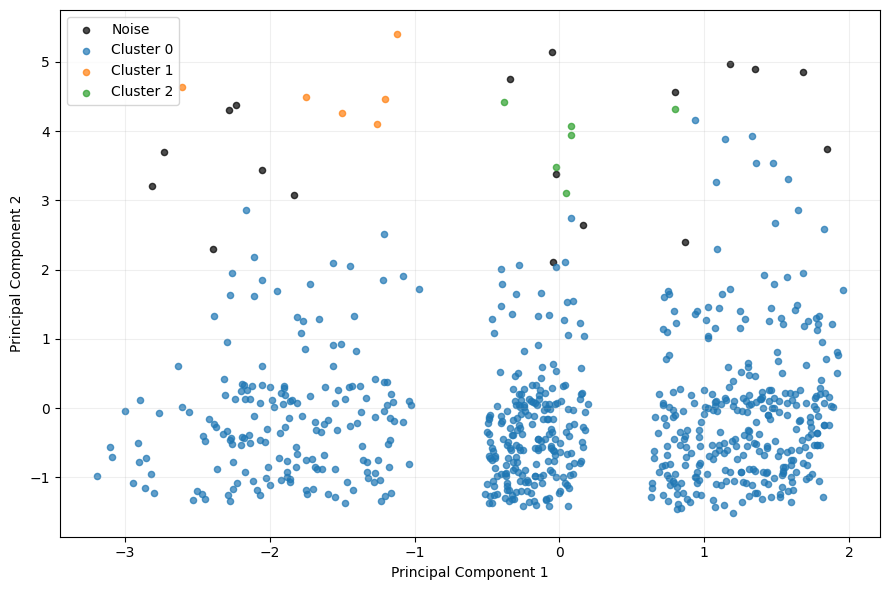

Explained Variance Ratio:
[0.4412 0.3854]

Total Explained Variance: 82.66 %


In [27]:
pca_dbscan3 = PCA(n_components=2)
X3_pca_dbscan = pca_dbscan3.fit_transform(X3_scaled)

plt.figure(figsize=(9, 6))
for cluster in sorted(set(clusters_dbscan3)):
    mask = clusters_dbscan3 == cluster
    if cluster == -1:
        plt.scatter(
            X3_pca_dbscan[mask, 0],
            X3_pca_dbscan[mask, 1],
            c="black",
            s=20,
            alpha=0.7,
            label="Noise"
        )
    else:
        plt.scatter(
            X3_pca_dbscan[mask, 0],
            X3_pca_dbscan[mask, 1],
            s=20,
            alpha=0.7,
            label=f"Cluster {cluster}"
        )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Explained Variance Ratio:")
print(pca_dbscan3.explained_variance_ratio_.round(4))
print("\nTotal Explained Variance:", round(pca_dbscan3.explained_variance_ratio_.sum() * 100, 2),"%")

In the case of PCA visualization, one main cluster, two smaller clusters, and some noise points were detected. The first two principal components captured 82.66% of variance, which means that they gave a more informative representation of the data features compared to previous datasets. Despite the good Silhouette score (0.5352), DBSCAN detected the very unbalanced clusters, meaning that it mostly detected some separate company clusters instead of customers’ clusters. Therefore, DBSCAN might be good for finding some rare companies but not for segmentation.

### Hierarchical Agglomerative Clustering: Linkage Comparison

Single, complete, average, and Ward linkage will be compared across 2 to 6 clusters using Silhouette scores and group sizes.

In [28]:
X3_hac = X3_scaled
linkage_methods3 = ["single", "complete", "average", "ward"]
cluster_counts3 = range(2, 7)
hac_results3 = []

for method in linkage_methods3:
    for k in cluster_counts3:
        hac = AgglomerativeClustering(
            n_clusters=k,
            linkage=method,
            metric="euclidean"
        )

        labels = hac.fit_predict(X3_hac)
        score = silhouette_score(
            X3_hac,
            labels
        )

        hac_results3.append({
            "Linkage": method,
            "Clusters": k,
            "Silhouette": round(score, 4)
        })

hac_results3_df = pd.DataFrame(hac_results3)

print("HAC Linkage Comparison:")
print(hac_results3_df.to_string(index=False))

HAC Linkage Comparison:
 Linkage  Clusters  Silhouette
  single         2      0.5344
  single         3      0.4219
  single         4      0.4183
  single         5      0.4223
  single         6      0.4550
complete         2      0.5607
complete         3      0.3196
complete         4      0.3156
complete         5      0.3621
complete         6      0.3275
 average         2      0.5259
 average         3      0.4834
 average         4      0.4116
 average         5      0.3907
 average         6      0.3599
    ward         2      0.3047
    ward         3      0.3729
    ward         4      0.3528
    ward         5      0.3570
    ward         6      0.3427


The Silhouette value was 0.5607 for complete linkage, with 2 clusters; 0.5344 for single linkage, and 0.5259 for average linkage. For 3 clusters, ward linkage gave the best Silhouette value of 0.3729. This is an indication of better cluster separation when compared to the previous data sets, but still, the distribution of the clusters needs to be checked to establish their significance.

### HAC Dendrogram

A Ward-linkage dendrogram will show the final 20 company-group merges.

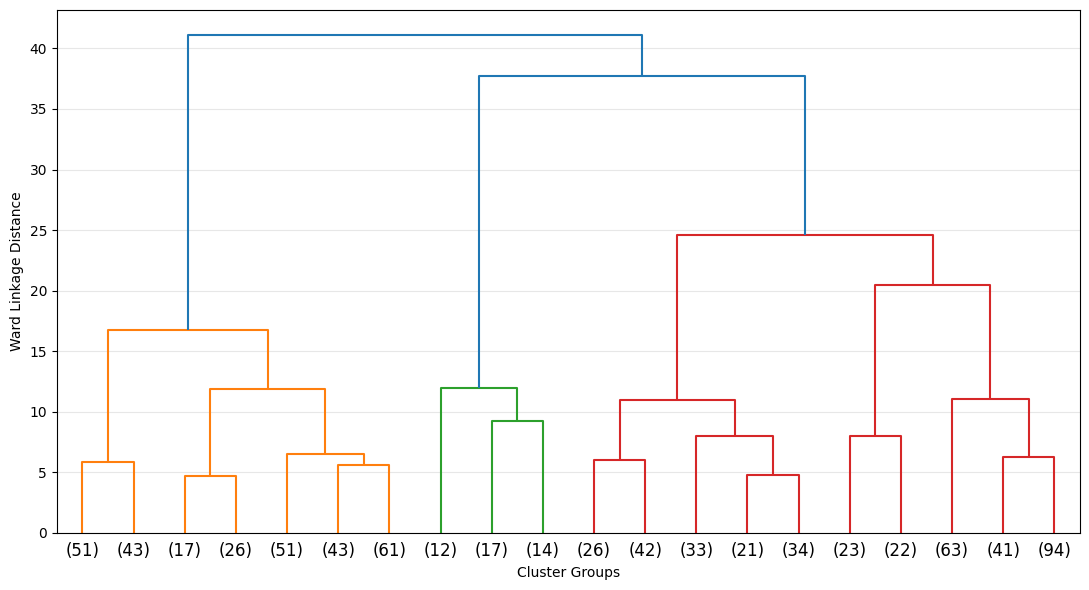

In [29]:
linkage_matrix3 = linkage(
    X3_hac,
    method="ward",
    metric="euclidean"
)

plt.figure(figsize=(11, 6))

dendrogram(
    linkage_matrix3,
    truncate_mode="lastp",
    p=20,
    show_leaf_counts=True
)

plt.xlabel("Cluster Groups")
plt.ylabel("Ward Linkage Distance")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Showed three different business firms, where the last merge happened at around 25, 38, and 41. The larger distance implies that the three clusters could be used to split the dataset, as seen by the maximum Silhouette value of 0.3729 in Ward linkage.

### HAC Cluster Distribution Comparison

Linkage analysis will be completed with complete linkage and two clusters, while Ward linkage will be done with three clusters.

In [30]:
hac_configs3 = [
    ("complete", 2),
    ("ward", 3)
]

for method, k in hac_configs3:
    hac = AgglomerativeClustering(
        n_clusters=k,
        linkage=method,
        metric="euclidean"
    )

    labels = hac.fit_predict(X3_hac)

    print(f"\n{method.capitalize()} Linkage:")
    print(pd.Series(labels).value_counts().sort_index())
    print("Silhouette Score:", round(silhouette_score(X3_hac, labels), 4))


Complete Linkage:
0    708
1     26
Name: count, dtype: int64
Silhouette Score: 0.5607

Ward Linkage:
0    399
1    292
2     43
Name: count, dtype: int64
Silhouette Score: 0.3729


Complete linkage gave the maximum Silhouette value of 0.5607 but grouped 708 companies in just one cluster, whereas Ward linkage gave three better clusters of 399, 292, and 43 companies. In spite of the fact that its Silhouette value was less at 0.3729, Ward linkage was chosen because it segmented companies better.

### HAC Cluster Characteristics

Comparison between the three Ward linkages will be made using the average values for company attributes and active contracts.

In [31]:
hac3 = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward",
    metric="euclidean"
)

clusters_hac3 = hac3.fit_predict(X3_hac)
df3_hac = df3.copy()
df3_hac["Cluster"] = clusters_hac3
df3_hac["Active_Contract"] = (df3_hac["Contract_Status"] == "Active").astype(int)

cluster_summary3 = df3_hac.groupby("Cluster").agg({
    "Annual_Revenue (M₺)": "mean",
    "Marketing_Spend (K₺)": "mean",
    "Days_Since_Last_Purchase": "mean",
    "Total_Purchases_Last_Year": "mean",
    "Active_Contract": ["count", "mean"]
})
cluster_summary3.columns = [
    "Annual_Revenue (M₺)",
    "Marketing_Spend (K₺)",
    "Days_Since_Last_Purchase",
    "Total_Purchases_Last_Year",
    "Company_Count",
    "Active_Contract_Rate"
]
cluster_summary3["Active_Contract_Rate"] *= 100

print("HAC Cluster Characteristics:")
print(cluster_summary3.round(2).to_string())

HAC Cluster Characteristics:
         Annual_Revenue (M₺)  Marketing_Spend (K₺)  Days_Since_Last_Purchase  Total_Purchases_Last_Year  Company_Count  Active_Contract_Rate
Cluster                                                                                                                                     
0                      10.70                 20.03                    162.56                       3.02            399                 69.42
1                      11.84                 20.51                     18.41                      11.56            292                 75.00
2                     133.17                 38.05                    117.02                       6.67             43                 74.42


Linkage of the Ward clustering method resulted in three segments of the company. Cluster 0 involved companies which were not very active and had a smaller number of purchases per year and had been made longer ago than in any other cluster. Cluster 1 included customers who were more frequent buyers, having the highest active contract rate of 75.00%. Cluster 2 included companies with high income and expenditures on marketing.

### HAC Cluster Visualization

PCA will reduce the four standardized features into two dimensions to visualize the three Ward linkage clusters and evaluate their separation.

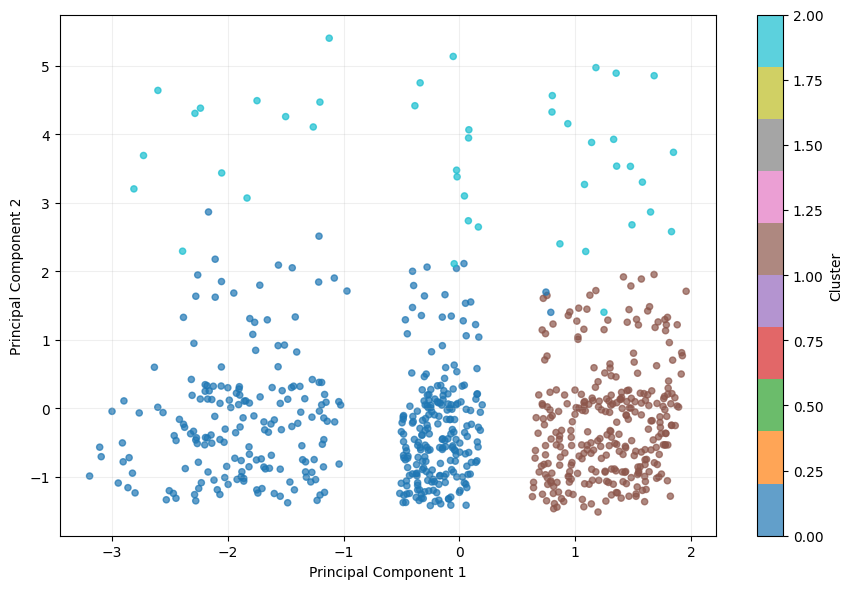

Explained Variance Ratio:
[0.4412 0.3854]

Total Explained Variance: 82.66 %


In [32]:
pca_hac3 = PCA(n_components=2)
X3_pca_hac = pca_hac3.fit_transform(X3_hac)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X3_pca_hac[:, 0],
    X3_pca_hac[:, 1],
    c=clusters_hac3,
    cmap="tab10",
    s=20,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Explained Variance Ratio:")
print(pca_hac3.explained_variance_ratio_.round(4))
print("\nTotal Explained Variance:", round(pca_hac3.explained_variance_ratio_.sum() * 100, 2), "%")


Revealed three well-separated clusters among companies with partial overlapping. First two Principal components explained 82.66% of total variability. In combination with Silhouette score equal to 0.3729, it proves that Ward linkage found differences in revenue and behavior of companies.

### Dataset 3 Conclusion

The performance of both DBSCAN and HAC in the Synthetic B2B CRM & Marketing dataset was superior to their performance on the other datasets. While DBSCAN had a Silhouette score of 0.5352, it allocated 704 out of 734 companies to a single cluster. While the best Silhouette score for HAC was that of complete linkage at 0.5607, this clustering method did not provide even allocation of observations. Ward linkage proved more useful for segmentation as it generated three clusters consisting of 399, 292, and 43 companies respectively with a Silhouette score of 0.3729.

## Overall Conclusion

The DBSCAN algorithm usually found only one main cluster, along with some other small clusters or noise points, making it unsuitable for general segmentation purposes. HAC gave better interpretability, especially in cases when Ward linkage was applied. Data Set 1 and Data Set 2 were poor in terms of clustering because there was no clear separation of the clusters. But Data Set 3 yielded better clusters which helped to segment companies in terms of their revenues and purchases. In general, the Ward linkage gave the best method of customer segmentation in the context of the Synthetic B2B CRM & Marketing data set.